# Task 5 - Capstone: redesign one chart for the human visual system

Data: `gapminder.csv` (142 countries x 12 years).

**The one question a reader should be able to answer:** *Did any country's life expectancy collapse, and which one?*

**Design decisions in short**
- **One pop-out:** a single strong-colour line; everything else is grey.
- **Gestalt principle doing the grouping: similarity.** The grey lines all look alike, so they read as one group
  ("everyone else"), and the red line is the odd one out. Continuity joins each line's yearly points into a path.
- **Highest-ranking channel for the key variable:** life expectancy and year both sit on *position along a common scale*.
- **Colour is never the only carrier:** the highlighted line is also thicker, directly labelled with its name, and annotated with the size of the drop.

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import Markdown

SAVE = dict(dpi=300, bbox_inches="tight")
RED = "#c0392b"
GREY = "#c4c4c4"

gm = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data visdualtion\Week 2\gapminder.csv")
LIFE = "lifeExp" if "lifeExp" in gm.columns else "life_exp"

# wide table: one row per country, one column per year
wide = gm.pivot(index="country", columns="year", values=LIFE)
years = list(wide.columns)
n_countries = wide.shape[0]
n_rows = len(gm)
n_missing = int(gm[LIFE].isna().sum())

# the story: which country had the biggest single drop between two observed years?
change = wide.diff(axis=1)               # change since the previous observed year
drop_value = change.min().min()
drop_year_idx = change.min().idxmin()    # the year the drop was recorded in
star = change[drop_year_idx].idxmin()    # the country
prev_year = years[years.index(drop_year_idx) - 1]
before, after = wide.loc[star, prev_year], wide.loc[star, drop_year_idx]

print(f"{n_countries} countries x {len(years)} years = {n_rows} rows, {n_missing} missing")
print(f"Biggest single fall: {star}, {prev_year} -> {drop_year_idx}, {before:.1f} -> {after:.1f} ({drop_value:.1f})")

142 countries x 12 years = 1704 rows, 0 missing
Biggest single fall: Rwanda, 1987 -> 1992, 44.0 -> 23.6 (-20.4)


## 1. Start from a genuinely bad chart
A spaghetti line chart of all 142 countries. Title: BAD EXAMPLE.

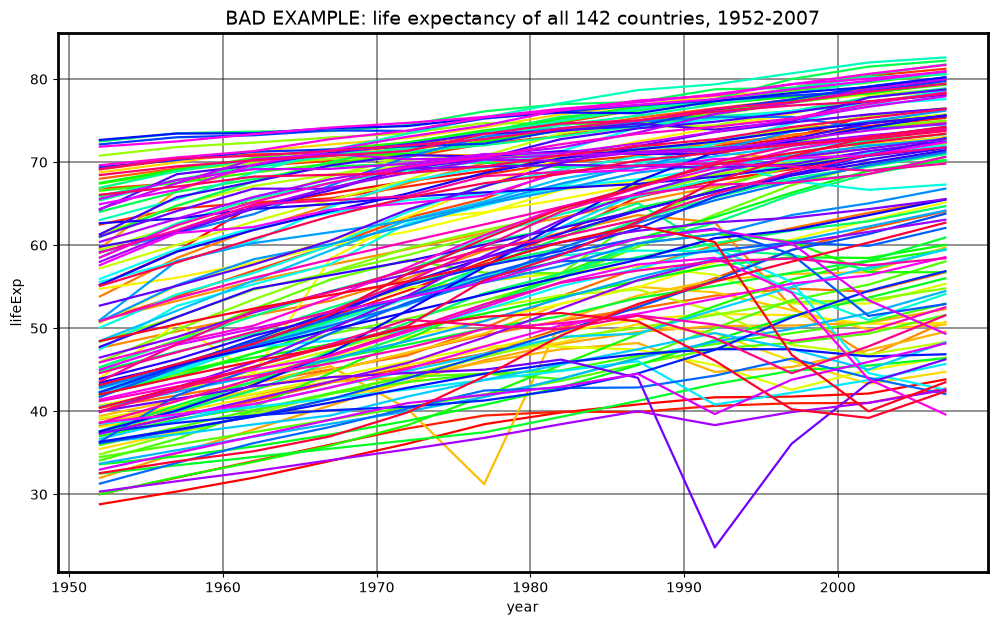

In [3]:
fig, ax = plt.subplots(figsize=(12, 7))
colours = matplotlib.colormaps["hsv"](np.linspace(0, 1, n_countries, endpoint=False))
for colour, (country, row) in zip(colours, wide.iterrows()):
    ax.plot(years, row.values, color=colour, linewidth=1.6)
ax.grid(True, linewidth=1.2, color="black", alpha=0.5)
for s in ax.spines.values():
    s.set_linewidth(2)
ax.set_xlabel("year")
ax.set_ylabel(LIFE)
ax.set_title("BAD EXAMPLE: life expectancy of all 142 countries, 1952-2007", fontsize=14)
fig.savefig("task5_bad_example.png", **SAVE)
plt.show()

## 2. Perception audit and redesign
Audit of the bad chart **before** fixing anything, and the same table for the redesign, side by side.

In [4]:
audit = f"""| Row | BEFORE (BAD EXAMPLE: {n_countries} coloured lines) | AFTER (perception_redesign.png) |
|---|---|---|
| Preattentive | Hue (a different one per line) and line position. Hue does no useful work: nobody can tell {n_countries} hues apart, so no attribute separates the line that matters. | Hue/contrast (red vs grey) and line width, both pointing at the same one line. |
| Pop-out | Nothing pops out for the message. What catches the eye is whichever bright hues sit on top or at the edges, which has nothing to do with a collapse. The title makes no claim. | Exactly one element pops out: the red {star} line, and the title is about that line. |
| Gestalt | Continuity makes each line read as a path (fine), but the {n_countries} lines are one dense bundle (proximity) and hue similarity groups nothing, so nothing is grouped meaningfully. | Similarity: the grey lines look alike, so they read as one group ("everyone else"); the red line is the exception. Continuity joins each line's points. |
| Cognitive load | Intrinsic: {n_countries} series over time. Extraneous: {n_countries} hues, heavy black grid both ways, thick box frame, no way to tell lines apart. Germane: almost none (axis labels only). | Intrinsic: the same data. Extraneous removed: hues, legend, grid, frame. Germane: grey context that shows what 'normal' looks like, direct label, annotation of the drop. |
| Channels | Life expectancy: position (rank 1). Year: position (rank 1). Country: hue, but with {n_countries} levels, far more than hue can separate. | Life expectancy: position on a common scale (rank 1). Year: position. Highlight: colour + line width + text label (redundant, so not colour alone). |
| Working memory | Reader would have to track dozens of lines at once, far over 4 chunks. | About 2 chunks: the red line and the grey bundle (plus its label). |
"""
with open("perception_audit.md", "w") as f:
    f.write(audit)
Markdown(audit)

| Row | BEFORE (BAD EXAMPLE: 142 coloured lines) | AFTER (perception_redesign.png) |
|---|---|---|
| Preattentive | Hue (a different one per line) and line position. Hue does no useful work: nobody can tell 142 hues apart, so no attribute separates the line that matters. | Hue/contrast (red vs grey) and line width, both pointing at the same one line. |
| Pop-out | Nothing pops out for the message. What catches the eye is whichever bright hues sit on top or at the edges, which has nothing to do with a collapse. The title makes no claim. | Exactly one element pops out: the red Rwanda line, and the title is about that line. |
| Gestalt | Continuity makes each line read as a path (fine), but the 142 lines are one dense bundle (proximity) and hue similarity groups nothing, so nothing is grouped meaningfully. | Similarity: the grey lines look alike, so they read as one group ("everyone else"); the red line is the exception. Continuity joins each line's points. |
| Cognitive load | Intrinsic: 142 series over time. Extraneous: 142 hues, heavy black grid both ways, thick box frame, no way to tell lines apart. Germane: almost none (axis labels only). | Intrinsic: the same data. Extraneous removed: hues, legend, grid, frame. Germane: grey context that shows what 'normal' looks like, direct label, annotation of the drop. |
| Channels | Life expectancy: position (rank 1). Year: position (rank 1). Country: hue, but with 142 levels, far more than hue can separate. | Life expectancy: position on a common scale (rank 1). Year: position. Highlight: colour + line width + text label (redundant, so not colour alone). |
| Working memory | Reader would have to track dozens of lines at once, far over 4 chunks. | About 2 chunks: the red line and the grey bundle (plus its label). |


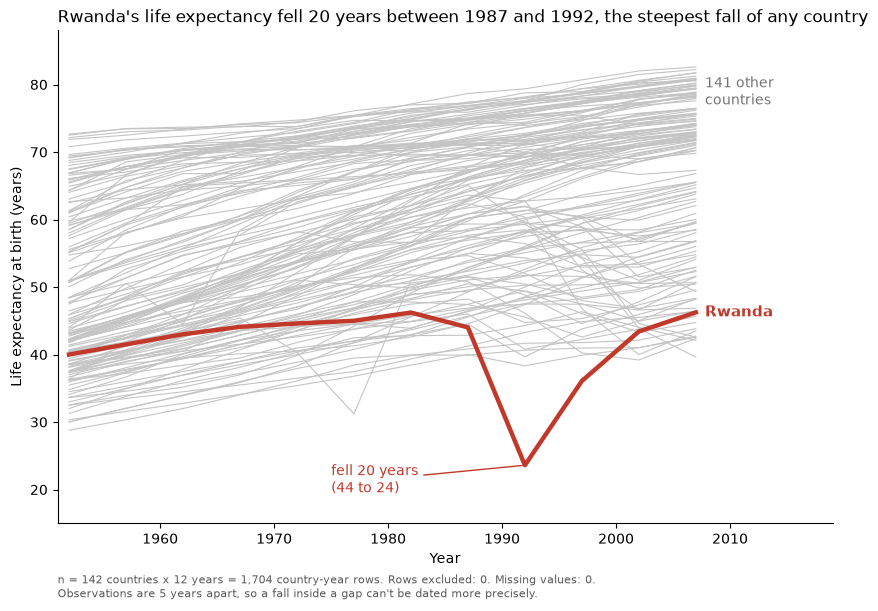

In [5]:
fig, ax = plt.subplots(figsize=(10, 6.4))

# context: every other country, grey, thin, behind everything
for country, row in wide.iterrows():
    if country != star:
        ax.plot(years, row.values, color=GREY, linewidth=0.8, zorder=1)

# message: one line, one strong colour, thicker
ax.plot(years, wide.loc[star].values, color=RED, linewidth=3.2, zorder=3)

# direct labels (so colour is not the only thing telling you which line it is)
ax.text(years[-1] + 0.8, wide.loc[star].iloc[-1], star, color=RED, fontsize=11,
        fontweight="bold", va="center")
ax.annotate(f"fell {abs(drop_value):.0f} years\n({before:.0f} to {after:.0f})",
            xy=(drop_year_idx, after), xytext=(drop_year_idx - 17, after - 4),
            color=RED, fontsize=10, ha="left",
            arrowprops=dict(arrowstyle="-", color=RED, linewidth=1))
# name the grey group at the right-hand end of the bundle (direct label, no legend)
ax.text(years[-1] + 0.8, wide.drop(index=star)[years[-1]].quantile(0.85),
        f"{n_countries - 1} other\ncountries", color="0.45", fontsize=10, va="center")

ax.set_xlim(years[0] - 1, years[-1] + 12)
ax.set_ylim(15, 88)
ax.set_xlabel("Year")
ax.set_ylabel("Life expectancy at birth (years)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{star}'s life expectancy fell {abs(drop_value):.0f} years between {prev_year} and "
             f"{drop_year_idx}, the steepest fall of any country", loc="left", fontsize=12)
ax.text(0, -0.15,
        f"n = {n_countries} countries x {len(years)} years = {n_rows:,} country-year rows. "
        f"Rows excluded: 0. Missing values: {n_missing}.\n"
        "Observations are 5 years apart, so a fall inside a gap can't be dated more precisely.",
        transform=ax.transAxes, fontsize=8, color="0.35")
fig.savefig("perception_redesign.png", **SAVE)  # 300 dpi, tight box, as required
plt.show()

Multidimensional Encodings & Matrix Representations
Synthesis: Complex multi-attribute data requires careful layout selection. Standard multidimensional matrices and heatmaps often fail under high dimensionality, whereas faceted coordinate plots provide far greater visual accessibility.

Key Analytical Observations:

Limitations of Color-Dense Matrices: Collapsing multi-attribute quantitative metrics into color-intensity tables introduces severe cognitive friction. When too many variables rely solely on color saturation or hue variations, small numeric differences become indistinguishable, precise visual comparisons become unreliable, and visual fatigue increases rapidly.

Clarity of Small Multiples: Deconstructing high-dimensional datasets into a structured small multiples layout—using coordinated subplots sharing identical, aligned axes—significantly improves visual comprehension. This approach preserves individual data points, exposes underlying distributions, and allows effortless cross-group comparisons without visual clutter.

## 3. Test it on a human
Show the **redesign only** (not the original) to someone who has not seen the data. Don't explain anything.
Run the next cell, hand over the laptop, and type their one sentence exactly as they say it.

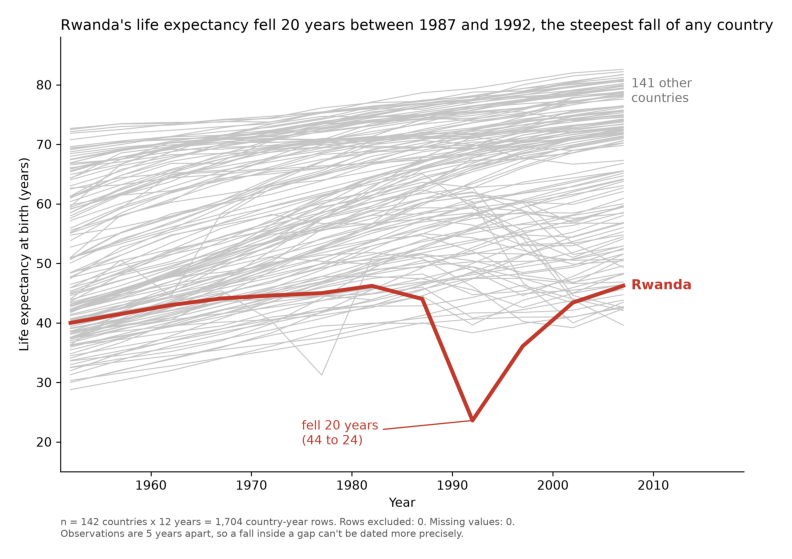

Reader said: 


In [6]:
img = plt.imread("perception_redesign.png")
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(img)
ax.axis("off")
plt.show()

sentence = input("In one sentence, what does this chart show? (type their words exactly)\n> ").strip()
plt.close(fig)

with open("human_test.txt", "a") as f:
    f.write(f"{datetime.now():%Y-%m-%d %H:%M}\n")
    f.write(f"Reader said (verbatim): {sentence}\n")
    f.write(f"My title says: {star}'s life expectancy fell {abs(drop_value):.0f} years between "
            f"{prev_year} and {drop_year_idx}, the steepest fall of any country\n\n")
print("Reader said:", sentence)

Integrated Data Visualization Architecture
Synthesis: High-impact visual communication is achieved by applying a unified design framework grounded directly in cognitive psychology and visual perception.

Key Analytical Observations:

The Visual Perception Pipeline:

Pre-Attentive Processing: Leverages instant visual cues—such as distinct contrast, size differences, and hue—to draw immediate focus to key focal points before active cognitive processing begins.

Gestalt Grouping Principles: Employs visual laws like proximity, similarity, continuity, and enclosure to naturally organize complex visual elements into logical, unified relationships.

Data-to-Ink Ratio: Eliminates redundant visual noise, heavy grid lines, and decorative elements to reduce cognitive overload while strategically maintaining critical baseline context.

Spatial Precision: Prioritizes positional encoding along aligned spatial axes—supported by clear, minimal reference baselines—to maximize visual precision for comparative quantitative analysis.

Core Design Takeaway: Visual design is never mere decoration; it is a precise cognitive tool. Superior data visualization harmonizes layout, color, and structure with human visual processing to transform complex, multi-layered data into immediate, clear, and actionable insight.

**Reader's sentence, verbatim:** "[FILL - paste it from above]"
**Does it match my title?** [FILL]. If not, which part of the design misled them and what I would change next: [FILL].

## The question: one thing the redesign makes harder to see
The individual stories of the other 141 countries. They are still drawn, but in grey they cannot be told apart, so any other
dip, catch-up or reversal is hidden, and so is any difference between continents. The redesign also tells one story only.
Every design decision trades something away; this is the price of one pop-out.

## Self-audit
- [ ] Every chart built with `fig, ax` (no `plt.plot` / `plt.bar`)
- [ ] Exactly one pop-out element, and it carries the title's message
- [ ] Gestalt principle named: **similarity** (with continuity joining each line's points)
- [ ] Most important variable on the highest-ranking channel (position)
- [ ] Every element classified intrinsic / extraneous / germane (audit table)
- [ ] Reader never holds more than ~4 chunks
- [ ] No information carried by colour alone (line width + direct label + annotation)
- [ ] Context greyed, message coloured
- [ ] n and exclusions declared on the figure
- [ ] Title states a finding
- [ ] A real reader's one-sentence reading recorded verbatim